# S&P 500 Long-short Strategy

This notebook presents the first three steps of the whole strategy pipeline - data collection and exploration, label engineering, and feature engineering. The rest of the model is moved to a separate notebook.

In [1]:
import yfinance as yf
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

## Collect the data

Load the Point-in-Time historical composition of the S&P 500 after Junuary 3, 2000. The file contains all changes to the index composition up to 2026-08-18. Any dates beyond this point reflect a static index composition, which is a known limitation of the project.

In [2]:
index_tickers = pl.read_csv("S&P 500 Historical Components & Changes (Updated).csv", try_parse_dates=True)

index_tickers = index_tickers.filter(pl.col("date") > pl.date(2000, 1, 1))

index_tickers = index_tickers.with_columns(
    pl.col("tickers").str.split(",").alias("tickers")
)

index_tickers = index_tickers.rename({
    "date" : "Date",
    "tickers" : "Tickers"
})

print(index_tickers)

shape: (2_228, 2)
┌────────────┬────────────────────────────┐
│ Date       ┆ Tickers                    │
│ ---        ┆ ---                        │
│ date       ┆ list[str]                  │
╞════════════╪════════════════════════════╡
│ 2000-01-03 ┆ ["AABA", "AAMRQ", … "YUM"] │
│ 2000-01-04 ┆ ["AABA", "AAMRQ", … "YUM"] │
│ 2000-01-05 ┆ ["AABA", "AAMRQ", … "YUM"] │
│ 2000-01-06 ┆ ["AABA", "AAMRQ", … "YUM"] │
│ 2000-01-07 ┆ ["AABA", "AAMRQ", … "YUM"] │
│ …          ┆ …                          │
│ 2026-06-24 ┆ ["A", "AAPL", … "ZTS"]     │
│ 2026-06-29 ┆ ["A", "AAPL", … "ZTS"]     │
│ 2026-06-30 ┆ ["A", "AAPL", … "ZTS"]     │
│ 2026-08-05 ┆ ["A", "AAPL", … "ZTS"]     │
│ 2026-08-18 ┆ ["A", "AAPL", … "ZTS"]     │
└────────────┴────────────────────────────┘


Extract the full set of tickers appearing in the index after January 3, 2000:

In [3]:
all_tickers = (
    index_tickers
    .explode("Tickers", empty_as_null=True)
    .select("Tickers")
    .unique()
    .to_series()
    .to_list()
)

print(f"Number of unique tickers in the index since 2000-01-03: {len(all_tickers)}")

Number of unique tickers in the index since 2000-01-03: 1096


Load the adjusted OHLCV data for all tickers from the historical index composition starting from 1998-01-01 to privide a buffer for long-term backward-looking features (e.g., 252-, 126-, 63-day momentum):

In [ ]:
batch_size = 50
all_prices = []

for i in range(0, len(all_tickers), batch_size):
    batch = all_tickers[i:i+batch_size]

    data = yf.download(batch, start="1998-01-01", end="2026-11-01", auto_adjust=True, group_by="ticker")

    for ticker in batch:
        if ticker in data.columns.levels[0]:
            ticker_price = data[ticker].reset_index()
            ticker_price["Symbol"] = ticker
            all_prices.append(ticker_price)

    time.sleep(1)

all_prices = pd.concat(all_prices, ignore_index=True)

all_prices = pl.from_pandas(all_prices).with_columns(
    pl.col("Date").cast(pl.Date).alias("Date")
)

all_prices.write_parquet("all_prices.parquet")

In [4]:
all_prices = pl.read_parquet("all_prices.parquet")

Check `all_prices` dataset for invalid values. This filter captures both genuine data errors and minor discrepancies caused by floating-point rounding after price adjustments. We allow a tiny tolerance (1e-5) for valid OHLCV bounds to avoid false positives from rounding errors.

In [5]:
all_prices.filter(
    (pl.min_horizontal("Open", "High", "Low", "Close") <= 0)
    | (pl.col("High") < pl.col("Low"))
    | (pl.max_horizontal("Open", "Close") > pl.col("High") * (1 + 1e-5))
    | (pl.min_horizontal("Open", "Close") < pl.col("Low") * (1 - 1e-5))
)

Date,Open,High,Low,Close,Volume,Symbol,Adj Close
date,f64,f64,f64,f64,f64,str,f64
2021-05-05,179.748096,182.187786,179.959056,181.720032,127234.0,"""HUBB""",null
2015-02-20,2280.000977,2904.001221,2628.000977,2851.201172,193.0,"""COMS""",null
2021-05-05,20.870001,21.825001,21.0,21.129999,5.213105e6,"""UA""",null


We have only 3 clear (although small) errors, so we fix these descrepancies manually:

In [6]:
all_prices = all_prices.with_columns(
    pl.max_horizontal("Open", "High", "Close").alias("High"),
    pl.min_horizontal("Open", "Low", "Close").alias("Low")
)

Remove tickers without available price history (e.g., companies that were delisted, went bunkrupt, were acquired or changed tickers) and keep only those with data. Note that this technical limitation introduces **survivorship bias** affecting the final results.

In [7]:
all_prices = (
    all_prices
    .drop("Adj Close")
    .filter(~pl.all_horizontal(pl.col(["Open", "High", "Low", "Close", "Volume"]).is_null()))
    .sort("Date")
)

To work with the Volume data and construct volume-based features later, we need to treat observations with zero volume carefully. For this, we explore the data for zero volume values:

In [9]:
zero = all_prices.filter(pl.col("Volume") == 0)

print(f"Number of zero-volume observations in all_prices: {zero.height}")
print(f"Number of unique symbols with zero-volume observations in all_prices: {zero['Symbol'].n_unique()}")
print(f'Distribution of zero-volume rows across labels: {zero.group_by("Symbol").len().sort("len", descending=True).head(10)}')
print(f'Number of rows with no any price movements throughout the day: {zero.filter((pl.col("Open") == pl.col("Close")) & (pl.col("High") == pl.col("Low"))).height}')

Number of zero-volume observations in all_prices: 18527
Number of unique symbols with zero-volume observations in all_prices: 95
Distribution of zero-volume rows across labels: shape: (10, 2)
┌────────┬──────┐
│ Symbol ┆ len  │
│ ---    ┆ ---  │
│ str    ┆ u32  │
╞════════╪══════╡
│ CPWR   ┆ 2917 │
│ SW     ┆ 2772 │
│ EP     ┆ 2580 │
│ FERG   ┆ 2079 │
│ COMS   ┆ 1811 │
│ GR     ┆ 1514 │
│ AMCR   ┆ 1371 │
│ NLV    ┆ 606  │
│ SII    ┆ 506  │
│ PARA   ┆ 435  │
└────────┴──────┘
Number of rows with no any price movements throughout the day: 16614


We observe that most zero-volume rows come from frozen rows with no any price movements throughout the day. This means thewe were no actual quotes on those days, and Yahoo simply repeated the previous price. This can happen, for example, when Yahoo backfills dummy history for companies that started trading after the beginning of our observation period. We need to filter these fake prices.

To address this, we remove all frozen rows, treating them as uninformative for the reason above. Additionally, we replace all zero-volume values with null values in the remaining non-frozen rows to ensure the correct behavior of subsequent operations when constructing volume features.

In [10]:
is_frozen = (pl.col("Volume") == 0) & (pl.col("Open") == pl.col("Close")) & (pl.col("High") == pl.col("Low"))

all_prices = (
    all_prices.filter(~is_frozen)
    .with_columns(pl.when(pl.col("Volume") == 0).then(None).otherwise(pl.col("Volume")).alias("Volume"))
)

Check that all unwanted zero-volume values are indeed removed or handled:

In [11]:
print(f'Number of zero-volume observations in all_prices: {all_prices.filter(pl.col("Volume") == 0).height}')
print(f'Number of rows with null-volume values: {all_prices["Volume"].null_count()}')

Number of zero-volume observations in all_prices: 0
Number of rows with null-volume values: 1913


In [12]:
available_tickers = (
    all_prices
    .select("Symbol")
    .unique()
    .to_series()
    .to_list()
)

print(f"Number of all historical constituents since 1998-01-01 with available history: {len(available_tickers)}")

null_rows_count = all_prices.filter(
    pl.any_horizontal(pl.all().is_null())
).height

print(f"Number of rows containing null values: {null_rows_count}")

Number of all historical constituents since 1998-01-01 with available history: 711
Number of rows containing null values: 1913


Create the Point-in-Time OHLCV dataset for all index constituents. For this we align historical index membership with actual price data.

In [13]:
# Calendar of all trading days with available price history since 1998-01-01
calendar = all_prices.select("Date").unique().sort("Date")

# Daily index composition aligned with the trading calendar.
# It shows what companies were in the index on every trading day after 2000-01-03.
tickers_daily = (
    calendar
    .join(index_tickers, on="Date", how="left")
    .with_columns(pl.col("Tickers").forward_fill())
    .explode("Tickers", empty_as_null=True)
    .rename({"Tickers" : "Symbol"})
)

# Point-in-Time OHLCV dataset for all active index constituents.
index_OHLCV = (
    tickers_daily
    .join(all_prices, on=["Date", "Symbol"], how="inner")
    .sort("Date")
)

print(index_OHLCV)

shape: (2_400_255, 7)
┌────────────┬────────┬────────────┬────────────┬────────────┬────────────┬────────────┐
│ Date       ┆ Symbol ┆ Open       ┆ High       ┆ Low        ┆ Close      ┆ Volume     │
│ ---        ┆ ---    ┆ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---        │
│ date       ┆ str    ┆ f64        ┆ f64        ┆ f64        ┆ f64        ┆ f64        │
╞════════════╪════════╪════════════╪════════════╪════════════╪════════════╪════════════╡
│ 2000-01-03 ┆ COP    ┆ 7.595664   ┆ 7.616083   ┆ 7.391479   ┆ 7.401689   ┆ 1.862219e6 │
│ 2000-01-03 ┆ DLX    ┆ 5.410595   ┆ 5.423005   ┆ 5.23686    ┆ 5.323728   ┆ 924578.0   │
│ 2000-01-03 ┆ HRB    ┆ 4.587027   ┆ 4.626571   ┆ 4.395901   ┆ 4.409082   ┆ 939200.0   │
│ 2000-01-03 ┆ WOR    ┆ 4.667327   ┆ 4.756398   ┆ 4.346671   ┆ 4.524814   ┆ 1.064032e6 │
│ 2000-01-03 ┆ MBI    ┆ 13.105022  ┆ 13.120829  ┆ 12.709816  ┆ 13.073404  ┆ 665400.0   │
│ …          ┆ …      ┆ …          ┆ …          ┆ …          ┆ …          ┆ …          │

In [14]:
n_index_OHLCV = index_OHLCV.select("Symbol").n_unique()
print(f"Number of tickers in the final universe: {n_index_OHLCV}")

# List of tickers that have price data on Yahoo
prices_tickers = set(all_prices["Symbol"].unique().to_list())

# List of tickers that remained in the final universe
final_tickers = set(index_OHLCV["Symbol"].unique().to_list())

# The difference (tickers that have prices but didn't make it to the final dataset)
lost_tickers = prices_tickers - final_tickers

print(f"Lost tickers: {len(lost_tickers)}")
print(f"Examples of lost tickers: {list(lost_tickers)[:10]}")

Number of tickers in the final universe: 633
Lost tickers: 78
Examples of lost tickers: ['EMC', 'ADCT', 'PCL', 'DYN', 'GDT', 'ADT', 'PCS', 'COMS', 'SUB', 'UPC']


The final universe contains 633 tickers, whereas price data was successfully downloaded for 711 out of 1096 in the entire index history. The first loss (1096 -> 711) is caused by absence of available price history for delisted companies. The next reduction of 78 tickers (711 -> 633) is likely caused by ticker changes and corporate actions. For example, Facebook traded as "FB" before changing its ticker to "META", but Yahoo Finance stores the price history only for the new "META". Consequently, the whole history under the ticker "FB" is missing from the dataset.

Furthermore, the "FB" ticker was later reassigned to another company that was never part of the S&P 500. This means the "FB" prices downloaded from Yahoo actually belong to this unrelated company. This is just one example illustrating the nature of the 78-ticker reduction.

Explore the dataset by plotting the Point-in-Time number of available tickers in the index against the date. This shows how the index universe size changes over time and helps estimate the scale of survivorship bias.

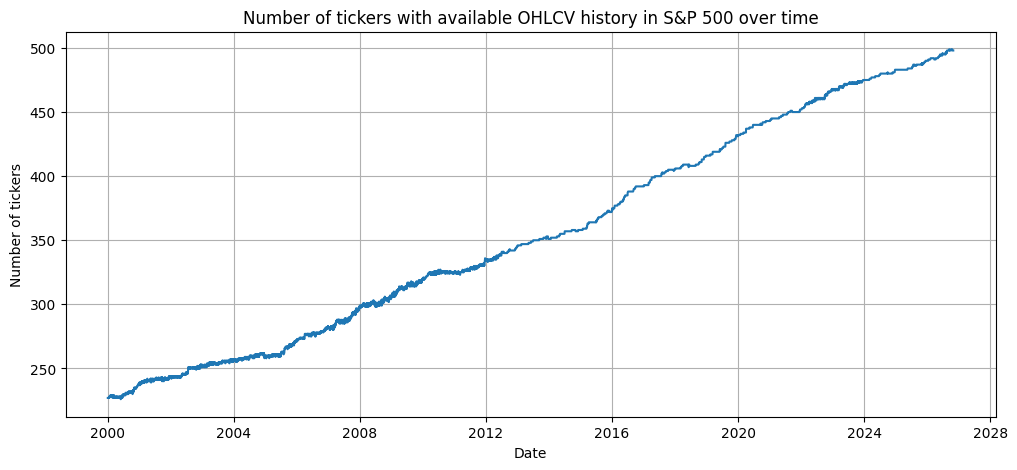

In [15]:
daily_counts = (
    index_OHLCV
    .group_by("Date")
    .agg(pl.col("Symbol").n_unique().alias("n_tickers"))
    .sort("Date")
)

dates = daily_counts["Date"].to_list()
counts = daily_counts["n_tickers"].to_list()

plt.figure(figsize=(12, 5))
plt.plot(dates, counts)
plt.title("Number of tickers with available OHLCV history in S&P 500 over time")
plt.xlabel("Date")
plt.ylabel("Number of tickers")
plt.grid()
plt.show()

The available ticker count shows a steady, nearly linear growth over the period. This is explained by data availability: the further back in time we go, the fewer historical tickers still have price data in Yahoo, primarily due to delistings and other reasons, so the early years look artificially sparse.

## Label Engineering

As a label, we choose the **cross-sectional rank of forward returns**. We use the simplest case of a fixed label horizon for all assets to avoid dealing with overlaping labels that arise from variable-horizon labels. Forward returns account only for trading days, so a signifiant unexplainable gap in an asset's price history breaks the idea of the label. To make all labels fair and consistent with the label definition, we identify all assets with gaps in their history greater than 10 calendar days between two consecutive trading days.

In [29]:
gaps = (
    index_OHLCV
    .sort(["Symbol", "Date"])
    .with_columns(
        pl.col("Date").diff().over("Symbol").dt.total_days().alias("Gap_days")
    )
    .filter(pl.col("Gap_days") > 10)
    .select(["Symbol", "Date", "Gap_days"])
    .sort("Gap_days", descending=True)
)

print(gaps)
print(f'Number of unique symbols with long gaps in their price history: {gaps.select(pl.col("Symbol").n_unique()).item()}')

shape: (125, 3)
┌────────┬────────────┬──────────┐
│ Symbol ┆ Date       ┆ Gap_days │
│ ---    ┆ ---        ┆ ---      │
│ str    ┆ date       ┆ i64      │
╞════════╪════════════╪══════════╡
│ CIEN   ┆ 2026-02-09 ┆ 5897     │
│ PTC    ┆ 2021-04-20 ┆ 5226     │
│ CNC    ┆ 2016-03-30 ┆ 4998     │
│ TT     ┆ 2020-03-03 ┆ 4289     │
│ JBL    ┆ 2023-12-18 ┆ 3331     │
│ …      ┆ …          ┆ …        │
│ GR     ┆ 2003-03-25 ┆ 11       │
│ GR     ┆ 2003-05-16 ┆ 11       │
│ GR     ┆ 2003-05-27 ┆ 11       │
│ GR     ┆ 2003-09-09 ┆ 11       │
│ GR     ┆ 2009-03-16 ┆ 11       │
└────────┴────────────┴──────────┘
Number of unique symbols with long gaps in their price history: 26


We have 125 gaps for 26 companies companies with long gaps in their history. There can be different reasons for this. For example, a company might be delisted and later re-included in the index under the same ticker (e.g., "AMD"). Another case is when a company is removed from the index, and later a different company takes over the same ticker and is also added to the index (e.g., "CNC").

This issue requires treating each case individually, which goes beyond the scope of the project and distracts from its main objective. Therefore, we consciosly remove these companies, excluding 4.1% of the universe to simplify the workflow.

In [30]:
gaps_list = (
    gaps
    .select(pl.col("Symbol"))
    .unique()
    .to_series()
    .to_list()
)

index_OHLCV = index_OHLCV.filter(
    ~pl.col("Symbol").is_in(gaps_list)
)

universe_size = index_OHLCV["Symbol"].n_unique()
print(f"Number of tickers in the final universe at this stage: {universe_size}")

Number of tickers in the final universe at this stage: 607


We use the **next-open-to-open convention**. It assumes that the signal is obtained by the end of the current trading day and can be executed only next morning by the open price. The rebalancing cadence is H=5 trading days.

The target variable is the cross-sectional rank of future H-day returns on each date. It is robust and not sensitive to outliers and exteme values of future returns.

In [31]:
# Fixed label horizon
H = 5

# Adjust the calendar of all trading days
# with entry and exit dates for each day
calendar = calendar.with_columns([
    pl.col("Date").shift(-1).alias("Entry_date"),
    pl.col("Date").shift(-(H + 1)).alias("Exit_date")
])

# Create an auxiliary dataframe avoiding changing the original index_OHLCV
df = index_OHLCV.join(calendar, on="Date", how="left")

# Extract open prices
prices_open = all_prices.select(["Date", "Symbol", "Open"])

# Get entry and exit prices for each asset
df = df.join(
    prices_open.rename({"Date" : "Entry_date", "Open" : "Entry_open"}),
    on=["Entry_date", "Symbol"],
    how="left"
)

df = df.join(
    prices_open.rename({"Date" : "Exit_date", "Open" : "Exit_open"}),
    on=["Exit_date", "Symbol"],
    how="left"
)

# Calculate forward returns and rank them cross-sectionally
df = df.with_columns(
    (pl.col("Exit_open") / pl.col("Entry_open") - 1).alias("Future_return")
)

Note that computing returns based on an adjusted price history using all further corporate actions history (which uses all subsequent corporate actions) does not introduce look-ahead bias, even though it relies on future information. Returns are safe in this context, but we should be careful with raw price levels rather than relative measures (like returns).

Look at the 5-day forward returns' distribution over the whole history to explore it and possibly spot outliers and errors:

shape: (9, 2)
┌────────────┬───────────────┐
│ statistic  ┆ Future_return │
│ ---        ┆ ---           │
│ str        ┆ f64           │
╞════════════╪═══════════════╡
│ count      ┆ 2.308717e6    │
│ null_count ┆ 0.0           │
│ mean       ┆ 0.002656      │
│ std        ┆ 0.048747      │
│ min        ┆ -0.916629     │
│ 25%        ┆ -0.019431     │
│ 50%        ┆ 0.003044      │
│ 75%        ┆ 0.024912      │
│ max        ┆ 6.425141      │
└────────────┴───────────────┘


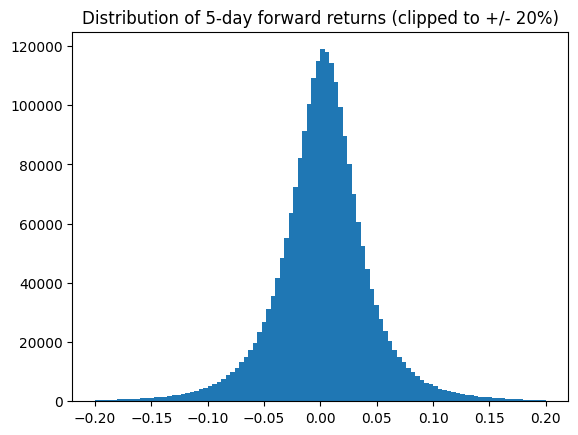

In [32]:
returns = df.select("Future_return").drop_nulls()

print(returns.describe()) 

plt.hist(returns.to_numpy(), bins=100, range=(-0.2, 0.2))
plt.title("Distribution of 5-day forward returns (clipped to +/- 20%)")
plt.show()

The distribution looks decent but clearly has some outliers. We look at them:

In [33]:
extreme_returns = (
    df.filter(pl.col("Future_return") > 2.0) # Growth by more than 200%. Any downfalls are considered to be valid.
    .select(["Date", "Symbol", "Future_return"])
    .sort("Future_return", descending=True)
)

print(extreme_returns)

extreme_returns_list = extreme_returns.select(pl.col("Symbol")).unique().to_series().to_list()

print(f"Companies with suspiciously extreme forward returns (more than 200%): {extreme_returns_list}")

shape: (9, 3)
┌────────────┬────────┬───────────────┐
│ Date       ┆ Symbol ┆ Future_return │
│ ---        ┆ ---    ┆ ---           │
│ date       ┆ str    ┆ f64           │
╞════════════╪════════╪═══════════════╡
│ 2025-06-12 ┆ PARA   ┆ 6.425141      │
│ 2025-06-11 ┆ PARA   ┆ 4.669649      │
│ 2025-06-10 ┆ PARA   ┆ 4.185786      │
│ 2025-06-06 ┆ PARA   ┆ 3.984066      │
│ 2009-03-11 ┆ AIG    ┆ 3.853662      │
│ 2025-06-09 ┆ PARA   ┆ 3.69923       │
│ 2002-07-25 ┆ WMB    ┆ 3.545456      │
│ 2002-07-24 ┆ WMB    ┆ 2.469566      │
│ 2009-03-12 ┆ AIG    ┆ 2.428572      │
└────────────┴────────┴───────────────┘
Companies with suspiciously extreme forward returns (more than 200%): ['PARA', 'WMB', 'AIG']


These records look suspicious, so we remove these companies from the dataset. Round values of forward returns (for example, 2.0) may indicate errors with splits adjustments. These are just 3 companies, and after removing them, we will still have 604 tickers in the universe, so this action does not affect the strategy significantly.

In [34]:
df = df.filter(
    ~pl.col("Symbol").is_in(extreme_returns_list)
)

Rank forward returns and normalise by the number of non-null values (using .count() instead of .len()) over the "Date" group:

In [35]:
df = df.with_columns(
    (pl.col("Future_return").rank().over("Date") / pl.col("Future_return").count().over("Date")).alias("Target")
)

In [36]:
n_null_targets = df.filter(pl.col("Target").is_null()).height
print(f"Number of rows with null-target: {n_null_targets}")

Number of rows with null-target: 2956


The target contains 2,956 null values out of 2,311,829 total values (0.13%). They come from the end of specific tickers' histories, where the exit price is unavailable and the forward return cannot be competed (e.g., due to delisting or end of the available history). Some number of nulls come from occasional small gaps in tickers' histories (shorter than 10 calendar days filtered out earlier), when the entry or exit date falls within such a gap.

In [38]:
universe = df.select(pl.col("Symbol")).unique().to_series().to_list()
universe_size = len(universe)
print(f"Number of tickers in the final universe at this stage: {universe_size}")

Number of tickers in the final universe at this stage: 604


After we have determined the final universe size and tickers included in the index and having valid price histories, we restrict `all_prices` to this universe:

In [39]:
all_prices = all_prices.filter(
    pl.col("Symbol").is_in(universe)
)

## Feature Engineering

### Momentum and mean reversion features

We calculate **5 momentum/mean-reversion features**: 12-, 6- and 3-month momentum with the last 21 days excluded so that mean reversion effects do not distory the signal. Additionally, we calculate 21- and 5-day reversions.

In [40]:
c = pl.col("Close")

mom_features = all_prices.select(
    "Date", "Symbol",
    (c.shift(21) / c.shift(252) - 1).over("Symbol").alias("Mom_12_1"),
    (c.shift(21) / c.shift(126) - 1).over("Symbol").alias("Mom_6_1"),
    (c.shift(21) / c.shift(63) - 1).over("Symbol").alias("Mom_3_1"),
    (c / c.shift(21) - 1).over("Symbol").alias("Rev_21d"),
    (c / c.shift(5) - 1).over("Symbol").alias("Rev_5d")
)

df = df.join(mom_features, on=["Date", "Symbol"], how="left")

# Convert the features into cross-sectional ranks
momentum_cols = ["Mom_12_1", "Mom_6_1", "Mom_3_1", "Rev_21d", "Rev_5d"]

df = df.with_columns(
        (pl.col(col).rank().over("Date") / pl.col(col).count().over("Date")).alias(f"{col}_rank")
        for col in momentum_cols
)

Then we calculate **the risk-adjusted `Mom_12_1_RA` feature** as `Mom_12_1` / `RV_12_1`.

In [41]:
# Define a log-return calculation operation
log_ret = (pl.col("Close") / pl.col("Close").shift(1)).log()

mom_risk_adj_features = all_prices.select(
    "Date", "Symbol",
    ((pl.col("Close").shift(21) / pl.col("Close").shift(252)).log() / (log_ret.shift(21).rolling_std(window_size=231) * np.sqrt(231))).over("Symbol").alias("Mom_12_1_RA")
)

df = df.join(mom_risk_adj_features, on=["Date", "Symbol"], how="left")

# Convert the feature into cross-sectional ranks
df = df.with_columns((pl.col("Mom_12_1_RA").rank().over("Date") / pl.col("Mom_12_1_RA").count().over("Date")).alias("Mom_12_1_RA_rank"))

### Volatility features

Firstly, we build 4 volatility features: **21- and 63-day realised volatility** level calculated both as a **standard deviation of log-returns** and using **Garman-Klass** formula.

In [42]:
vol_features = all_prices.select(
    "Date", "Symbol",
    (log_ret.rolling_std(window_size=21) * np.sqrt(252)).over("Symbol").alias("RV_21"),
    (log_ret.rolling_std(window_size=63) * np.sqrt(252)).over("Symbol").alias("RV_63")    
)

df = df.join(vol_features, on=["Date", "Symbol"], how="left")

In [43]:
# Garman-Klass realised volatility
GK_daily_var = 0.5 * (pl.col("High") / pl.col("Low")).log() ** 2 - (2 * np.log(2) - 1) * (pl.col("Close") / pl.col("Open")).log() ** 2

GK_features = all_prices.select(
    "Date", "Symbol",
    (GK_daily_var.rolling_mean(window_size=21) * 252).sqrt().over("Symbol").alias("GK_21"),
    (GK_daily_var.rolling_mean(window_size=63) * 252).sqrt().over("Symbol").alias("GK_63")
)

df = df.join(GK_features, on=["Date", "Symbol"], how="left")

In [44]:
# Convert the features into cross-sectional ranks
vol_cols = ["RV_21", "RV_63", "GK_21", "GK_63"]

df = df.with_columns(
    (pl.col(col).rank().over("Date") / pl.col(col).count().over("Date")).alias(f"{col}_rank")
    for col in vol_cols
)

Calculate **2 volatility ratio features**: the ratio of 5-day to 63-day realised volatility, calculated using both the standard deviation of log-returns and the Garman-Klass realised volatilty. This aims to reflect the current level of a  stock's volatility compared to its normal value.

In [45]:
ratio_features = all_prices.select(
    "Date", "Symbol",
    (log_ret.rolling_std(window_size=5) / log_ret.rolling_std(window_size=63)).over("Symbol").alias("RV_ratio"),
    (GK_daily_var.rolling_mean(window_size=5) / GK_daily_var.rolling_mean(window_size=63)).sqrt().over("Symbol").alias("GK_ratio")
)

df = df.join(ratio_features, on=["Date", "Symbol"], how="left")

# Convert the features into cross-sectional ranks
ratio_cols = ["RV_ratio", "GK_ratio"]

df = df.with_columns(
    (pl.col(col).rank().over("Date") / pl.col(col).count().over("Date")).alias(f"{col}_rank")
    for col in ratio_cols
)

### Market Model & Risk Decomposition Features

We build **4 market-adjusted features** based on the market model, a rolling regression of a stock's daily log returns on the market's daily log-returns: $r_i = \alpha + \beta \cdot r_{market} + \epsilon$. As the market proxy we use SPY (S&P 500 ETF).

$\beta$ here is the sensitivity of an asset's returns to overall market movements and calculated as $\beta = \text{cov} (r_i, r_{market}) / \text{Var} [r_{market}]$. Two features are built as **63- and 252-day regression of $\beta$**. These features reflect a systematic (market) part of the overall realised volatility.

The other two features are **daily annualised idiosyncratic volatility**, the standard deviation of the residuals: $\text{Var}[\epsilon] = \text{Var}[r_i] - \beta ^ 2 \text{Var}[r_{market}]$. These features reflect a stock-specific part of the overall realised volatility.

In [52]:
spy = yf.download("SPY", start="1998-01-01", end="2026-11-01", auto_adjust=True, multi_level_index=False).reset_index()

spy = pl.from_pandas(spy).select(
    pl.col("Date").cast(pl.Date),
    pl.col("Close").alias("Close_SPY")
).sort("Date")

spy.write_parquet("SPY.parquet")

[*********************100%***********************]  1 of 1 completed


In [46]:
spy = pl.read_parquet("SPY.parquet")

In [47]:
# Extract Point-in-Time daily log-returns for the index constituents and the market proxy SPY
returns = (
    all_prices.join(spy, on="Date", how="left")
    .sort("Date")
    .select(
        "Date", "Symbol",
        log_ret.over("Symbol").alias("Log_ret"),
        (pl.col("Close_SPY") / pl.col("Close_SPY").shift(1)).log().over("Symbol").alias("Ret_SPY")
    )
)

In [48]:
def market_model(window):
    var_spy = pl.col("Ret_SPY").rolling_var(window_size=window)
    beta = pl.rolling_cov("Log_ret", "Ret_SPY", window_size=window) / var_spy
    var_eps = pl.col("Log_ret").rolling_var(window_size=window) - beta ** 2 * var_spy
    return [
        beta.over("Symbol").alias(f"Beta_{window}"),
        (var_eps.clip(lower_bound=0) * 252).sqrt().over("Symbol").alias(f"IVOL_{window}")
    ]

capm_features = returns.select(
    "Date", "Symbol",
    *market_model(63),
    *market_model(252)
)

df = df.join(capm_features, on=["Date", "Symbol"], how="left")

# Convert the features into cross-sectional ranks
capm_cols = ["Beta_63", "Beta_252", "IVOL_63", "IVOL_252"]

df = df.with_columns(
    (pl.col(col).rank().over("Date") / pl.col(col).count().over("Date")).alias(f"{col}_rank")
    for col in capm_cols
)

### Tail Risk Features

Calculate the **21-day skeweness feature** (level of asymmetry):

$\text{Skew} =  \frac{\mathbb{E} [(r - \bar{r})^3]}{\sigma^3}$.

It shows which side of the distribution has a longer tail: Skew > 0 implies many small downward movements and rare sharp jumps up; Skew < 0 implies many small upward movements and rare sharp drops.

In [49]:
skew_features = all_prices.select(
    "Date", "Symbol",
    log_ret.rolling_skew(window_size=21).over("Symbol").alias("Skew_21")
)

df = df.join(skew_features, on=["Date", "Symbol"], how="left")

# Convert the feature into cross-sectional ranks
df = df.with_columns((pl.col("Skew_21").rank().over("Date") / pl.col("Skew_21").count().over("Date")).alias("Skew_21_rank"))

Calculate **the `Max_21` feature** - the maximum daily return of a stock over the last 21 trading days. More specifically, it is the strongest one-day gain within a month.

In [50]:
max_features = all_prices.select(
    "Date", "Symbol",
    log_ret.rolling_max(window_size=21).over("Symbol").alias("Max_21")
)

df = df.join(max_features, on=["Date", "Symbol"], how="left")

# Convert the feature into cross-sectional ranks
df = df.with_columns((pl.col("Max_21").rank().over("Date") / pl.col("Max_21").count().over("Date")).alias("Max_21_rank"))

### Volume Features

Volume data in the OHLCV table is split-adjusted, so its raw values cannot be compared directly across different assets. Instead, we construct dimensionless **volume ratios** within each individual asstet's history. These features encode how unusual the current volume is compared to its normal historical value.

In [51]:
feature_cols = [col for col in df.columns if col.endswith("_rank")]

panel = df.select(["Date", "Symbol", "Future_return", "Target"] + feature_cols).sort("Date")

panel.write_parquet("panel.parquet")